In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Load dataset

In [2]:
df = pd.read_csv("../../datasets/c_text_youm7/youm7_cleaned_data.csv")

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12089 entries, 0 to 12088
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   category_label  12089 non-null  str  
 1   title           12089 non-null  str  
 2   summary         12089 non-null  str  
dtypes: str(3)
memory usage: 5.1 MB


### Check the category distribution

In [9]:
def category_distribution(df: pd.DataFrame) -> pd.DataFrame:
    distribution = (
        df["category_label"]
        .value_counts()
        .rename("count")
        .to_frame()
    )

    distribution["percentage"] = (
        distribution["count"] / len(df) * 100
    ).round(2)

    return distribution

category_distribution(df)

,count,percentage
category_label,,
علوم_وتكنولوجيا,1879,15.54
سياسة_وأخبار_مصر,1783,14.75
محافظات_ومجتمع,1770,14.64
فن_وثقافة,1746,14.44
اقتصاد_وبورصة,1740,14.39
رياضة_مصرية,1683,13.92
حوادث_وقضايا,1488,12.31


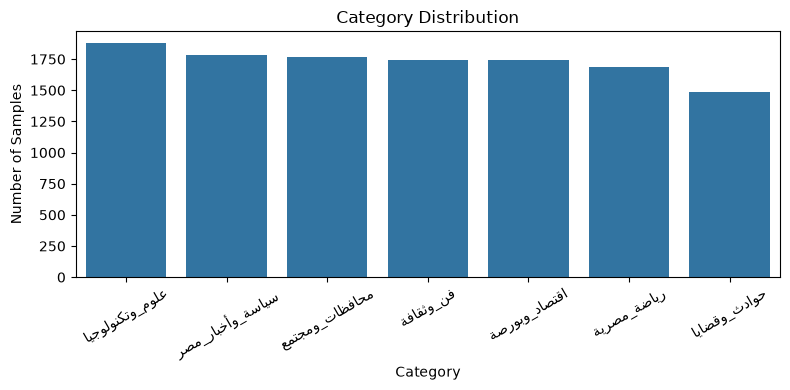

In [16]:
def plot_category_distribution(distribution: pd.DataFrame) -> None:

    plt.figure(figsize=(8, 4))

    sns.barplot(
        data=distribution.reset_index(),
        x="category_label",
        y="count"
    )

    plt.title("Category Distribution")
    plt.xlabel("Category")
    plt.ylabel("Number of Samples")
    plt.xticks(rotation=30)

    plt.tight_layout()
    plt.show()

plot_category_distribution(category_distribution(df))

### Check and Deal with Outliers

In [30]:
def text_count(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    for col in ["title", "summary"]:
        df[f"{col}_char_count"] = df[col].str.len()
        df[f"{col}_word_count"] = df[col].str.split().str.len()

    return df

In [40]:
def plot_length_distribution(df: pd.DataFrame, feature: str) -> None:
    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=df,
        x="category_label",
        y=feature
    )

    plt.title(f"{feature} Distribution by Category")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

In [41]:
df_count = text_count(df)

In [42]:
def detect_outliers(df: pd.DataFrame, feature: str) -> pd.DataFrame:
    results = []

    for category, group in df.groupby("category_label"):

        q1 = group[feature].quantile(0.25)
        q3 = group[feature].quantile(0.75)

        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        outliers = group[
            (group[feature] < lower) |
            (group[feature] > upper)
        ]

        results.append({
            "category": category,
            "total_samples": len(group),
            "outliers": len(outliers),
            "outlier_percentage": round(
                len(outliers) / len(group) * 100, 2
            )
        })

    results_df = pd.DataFrame(results)

    print(f"Average Outlier Percentage: " f"{results_df['outlier_percentage'].mean():.2f}%")
    return results_df

In [43]:
detect_outliers(df_stats, "title_word_count")

Average Outlier Percentage: 1.07%


,category,total_samples,outliers,outlier_percentage
0,اقتصاد_وبورصة,1740,17,0.98
1,حوادث_وقضايا,1488,13,0.87
2,رياضة_مصرية,1683,7,0.42
3,سياسة_وأخبار_مصر,1783,50,2.80
4,علوم_وتكنولوجيا,1879,10,0.53
5,فن_وثقافة,1746,18,1.03
6,محافظات_ومجتمع,1770,15,0.85


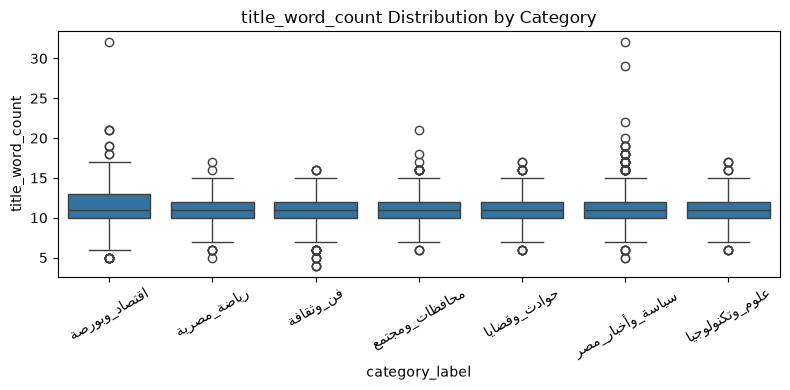

In [44]:
plot_length_distribution(df_count, "title_word_count")

In [45]:
detect_outliers(df_stats, "summary_word_count")

Average Outlier Percentage: 1.64%


,category,total_samples,outliers,outlier_percentage
0,اقتصاد_وبورصة,1740,17,0.98
1,حوادث_وقضايا,1488,45,3.02
2,رياضة_مصرية,1683,21,1.25
3,سياسة_وأخبار_مصر,1783,25,1.40
4,علوم_وتكنولوجيا,1879,30,1.60
5,فن_وثقافة,1746,26,1.49
6,محافظات_ومجتمع,1770,31,1.75


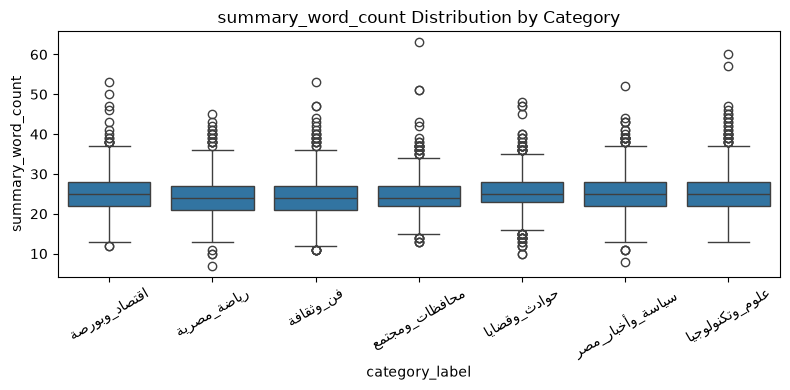

In [46]:
plot_length_distribution(df_count, "summary_word_count")

In [ ]:
feature = "summary_word_count"

q1 = df_stats[feature].quantile(0.25)
q3 = df_stats[feature].quantile(0.75)

upper = q3 + 1.5 * (q3 - q1)

outliers_df = df_stats[df_stats[feature] > upper][["category_label", "title", "summary", feature]]

In [ ]:
def inspect_text_quality(df: pd.DataFrame,text_col: str) -> pd.DataFrame:
    result = df.copy()

    result["has_url"] = result[text_col].str.contains(
        r"https?://|www\.",
        regex=True,
        case=False,
        na=False
    )

    result["has_html"] = result[text_col].str.contains(
        r"<[^>]+>|&[a-zA-Z]+;",
        regex=True,
        na=False
    )

    result["has_repeated_chars"] = result[text_col].str.contains(
        r"(.)\1{4,}",
        regex=True,
        na=False
    )

    result["has_unusual_symbols"] = result[text_col].str.contains(
        r"[^\u0600-\u06FF\u0750-\u077F"
        r"\u08A0-\u08FF\uFB50-\uFDFF"
        r"\uFE70-\uFEFFa-zA-Z0-9\s.,!?،؛:؟()\-_]",
        regex=True,
        na=False
    )

    return result

In [69]:
title_quality = inspect_text_quality(outliers_df,"title")
summary_quality = inspect_text_quality(outliers_df,"summary")

/tmp/ipykernel_86220/1190656533.py:21: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  result["has_repeated_chars"] = result[text_col].str.contains(
/tmp/ipykernel_86220/1190656533.py:21: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  result["has_repeated_chars"] = result[text_col].str.contains(


In [70]:
display(title_quality[summary_quality["has_url"] | summary_quality["has_html"] | summary_quality["has_repeated_chars"] | summary_quality["has_unusual_symbols"]])

,category_label,title,summary,summary_word_count,has_url,has_html,has_repeated_chars,has_unusual_symbols


In [68]:
display(summary_quality[summary_quality["has_url"] | summary_quality["has_html"] | summary_quality["has_repeated_chars"] | summary_quality["has_unusual_symbols"]])

,category_label,title,summary,summary_word_count,has_url,has_html,has_repeated_chars,has_unusual_symbols


In [ ]:
outliers_df.to_csv("../../datasets/c_text_youm7/youm7_outliers_summary_word_count.csv", index=False)

### Drop the title and works on the summary column only as the title is too short and not informative enough

In [73]:
df.drop(columns=["title"], inplace=True)

/tmp/ipykernel_86220/3277199948.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["title"], inplace=True)


In [74]:
df.head()

,category_label,summary
0,اقتصاد_وبورصة,ينشر اليوم السابع أسعار أسهم أكبر 5 شركات حققت...
1,اقتصاد_وبورصة,ارتفعت أسعار الذهب في السوق المصري بنحو 15 جني...
2,اقتصاد_وبورصة,أصدرت وزارة البترول والثروة المعدنية إنفوجرافا...
3,اقتصاد_وبورصة,تنوعت أخبار البورصة المصرية خلال جلسة تداول ال...
4,اقتصاد_وبورصة,استقر سعر الدولار أمام الجنيه المصرى اليوم الأ...


In [106]:
def add_text_statistics(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    df["char_count"] = df["summary"].str.len()
    df["word_count"] = (df["summary"].str.split().str.len())
    df["unique_word_count"] = (df["summary"].apply(lambda text: len(set(text.split()))))
    df["lexical_diversity"] = (df["unique_word_count"] / df["word_count"].replace(0, pd.NA))

    return df

In [93]:
eda_df = add_text_statistics(df)

In [94]:
eda_df.head()

,category_label,summary,char_count,word_count,unique_word_count,lexical_diversity
0,اقتصاد_وبورصة,ينشر اليوم السابع أسعار أسهم أكبر 5 شركات حققت...,143,24,20,0.833333
1,اقتصاد_وبورصة,ارتفعت أسعار الذهب في السوق المصري بنحو 15 جني...,90,16,16,1.000000
2,اقتصاد_وبورصة,أصدرت وزارة البترول والثروة المعدنية إنفوجرافا...,165,23,21,0.913043
3,اقتصاد_وبورصة,تنوعت أخبار البورصة المصرية خلال جلسة تداول ال...,129,19,14,0.736842
4,اقتصاد_وبورصة,استقر سعر الدولار أمام الجنيه المصرى اليوم الأ...,126,21,20,0.952381


In [77]:
def text_statistics(df: pd.DataFrame) -> pd.DataFrame:
    features = [
        "char_count",
        "word_count",
        "unique_word_count",
        "lexical_diversity"
    ]

    return df[features].describe().T

In [95]:
text_statistics(eda_df)

,count,mean,std,min,25%,50%,75%,max
char_count,12089.0,150.674663,27.829890,42.00,133.000000,150.0,167.0,404.0
word_count,12089.0,24.674249,4.660187,7.00,22.000000,25.0,27.0,63.0
unique_word_count,12089.0,23.839027,4.340095,6.00,21.000000,24.0,26.0,55.0
lexical_diversity,12089.0,0.968217,0.041238,0.64,0.952381,1.0,1.0,1.0


In [107]:

def plot_text_distribution(df: pd.DataFrame, feature: str, bins: int, title: str) -> None:
    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df,
        x=feature,
        bins=bins,
        kde=True
    )

    plt.title(title)
    plt.xlabel(feature.replace("_", " ").title())
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()


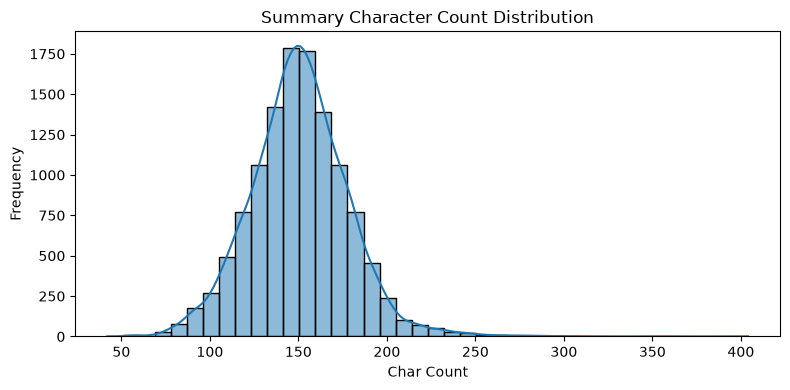

In [108]:
plot_text_distribution(
    eda_df,
    feature="char_count",
    bins=40,
    title="Summary Character Count Distribution"
)

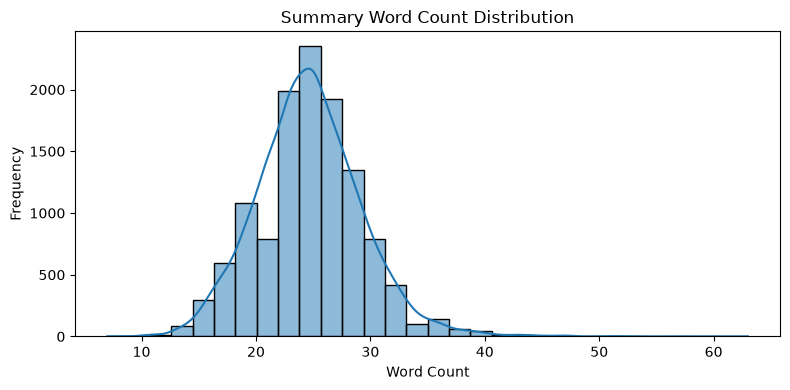

In [109]:

plot_text_distribution(
    eda_df,
    feature="word_count",
    bins=30,
    title="Summary Word Count Distribution"
)

In [100]:
category_statistics = (
    eda_df.groupby("category_label")
    .agg(
        samples=("summary", "count"),
        avg_words=("word_count", "mean"),
        median_words=("word_count", "median"),
        std_words=("word_count", "std"),
        avg_chars=("char_count", "mean"),
        avg_unique_words=("unique_word_count", "mean"),
        avg_lexical_diversity=("lexical_diversity", "mean")
    )
    .round(3)
)

display(category_statistics)

,samples,avg_words,median_words,std_words,avg_chars,avg_unique_words,avg_lexical_diversity
category_label,,,,,,,
اقتصاد_وبورصة,1740,25.137,25.0,4.619,154.018,23.922,0.954
حوادث_وقضايا,1488,25.397,25.0,4.495,154.247,24.699,0.974
رياضة_مصرية,1683,23.884,24.0,4.781,143.652,23.244,0.975
سياسة_وأخبار_مصر,1783,25.207,25.0,4.574,157.097,24.344,0.968
علوم_وتكنولوجيا,1879,24.813,25.0,4.968,149.049,23.966,0.968
فن_وثقافة,1746,23.928,24.0,4.862,142.688,23.200,0.972
محافظات_ومجتمع,1770,24.416,24.0,3.994,154.197,23.588,0.968


In [102]:
from collections import Counter

all_words = " ".join(eda_df["summary"]).split()

word_frequency = Counter(all_words)

most_common_words = pd.DataFrame(
    word_frequency.most_common(30),
    columns=["word", "frequency"]
)

display(most_common_words)

,word,frequency
0,في,6843
1,من,5726
2,على,4021
3,اليوم,2349
4,إلى,2010
5,عن,1784
6,خلال,1685
7,مع,1457
8,2026,1372
9,مصر,1324


In [104]:
from collections import Counter

category_word_frequency = {}

for category in eda_df["category_label"].unique():
    category_text = " ".join(eda_df.loc[eda_df["category_label"] == category, "summary"])
    category_word_frequency[category] = Counter(category_text.split())

for category, counter in category_word_frequency.items():
    print(f"\n{'=' * 50}")
    print(category)
    print("=" * 50)

    for word, frequency in counter.most_common(15):
        print(f"{word:<20} {frequency}")



اقتصاد_وبورصة
في                   1309
اليوم                786
2026                 774
سعر                  640
من                   610
الذهب                529
خلال                 469
المصرية              433
نوفمبر               411
تعاملات              392
مصر                  392
جنيه                 382
أسعار                373
الجنيه               367
على                  345

رياضة_مصرية
في                   987
من                   765
على                  615
مصر                  545
الأهلي               425
لكرة                 403
اليوم                383
القدم                375
بطولة                360
كأس                  354
الفريق               351
الأول                342
منافسات              341
الفني                324
المصري               324

فن_وثقافة
في                   1194
من                   1041
على                  453
عن                   423
إلى                  303
خلال                 258
مهرجان               245
الفنان               237
اليوم   

# Notes for the next steps:

- then the most repeted words are arabic stopwords, so we will remove them in the nlp preprocessing step
- remove words like 'نوفمبر'
- remove numbers